# Ejercicio de Variables Cuantitativa
![logo Itq](img/ITQ.png)

**Nombre:** Freddy Guevara

**Fecha** *25-11-2026*

**Variables cuantitativas:** son las que se expresan con números, como la edad, el precio o la temperatura. Para entenderlas calculamos medidas que las resumen: de **tendencia central** (dónde se concentran los datos), de **posición** (cuartiles y valores atípicos), de **dispersión** (qué tan separados están) y de **distribución** (qué forma tienen: asimetría y curtosis). Primero las aplicamos a un conjunto de datos creado por nosotros y luego al dataset Iris.

**Link Repositorio** https://github.com/Fguevara92/Fund_Machin_Learn_IA_Noct_26_27/blob/main/Programa13_Variables_Cuantitativa.ipynb

### Importación de librerías
* **numpy**: manejo de arreglos y cálculos como la media, la mediana y los percentiles.
* **matplotlib.pyplot**: para dibujar gráficos.
* **scipy.stats**: para calcular la moda, la asimetría y la curtosis.

In [10]:
# Importamos Librerias para la creacion de datos
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Creación de los datos
Creamos el arreglo `X` con 16 valores, positivos y negativos. Incluimos a propósito valores muy alejados (como -100 y 60) para ver después cómo afectan a las medidas.

In [11]:
# Creamos los datos

X = np.array([0.5, 23, 0.3, 4.5, 0.3, 0.5,
-28, -50, 60, -100, -10, -11, 13, 19, 1, 9])
print(X)

[   0.5   23.     0.3    4.5    0.3    0.5  -28.   -50.    60.  -100.
  -10.   -11.    13.    19.     1.     9. ]


**Interpretación:** los datos están muy repartidos: hay valores pequeños cerca de 0 y otros muy lejanos. Esto nos servirá para detectar valores atípicos más adelante.

### Medidas de tendencia central
* **Media** (`np.mean`): el promedio de todos los valores.
* **Mediana** (`np.median`): el valor del centro cuando ordenamos los datos.
* **Moda** (`stats.mode`): el valor que más se repite.

In [3]:
# Calculamos medidas de tendencia central

media = np.mean(X)
mediana = np.median(X)
moda , _ = stats.mode(X)
print('La media de los datos es: ', media)
print('La mediana de los datos es: ', mediana)
print('La moda de los datos es :', moda)

La media de los datos es:  -4.24375
La mediana de los datos es:  0.5
La moda de los datos es : 0.3


**Interpretación:** la media es **-4,24** y la mediana es **0,5**. Como son diferentes, hay valores extremos que jalan el promedio hacia abajo. La moda es **0,3**, que aparece dos veces; el 0,5 también se repite dos veces, pero `stats.mode` devuelve el menor de los empatados. Aquí la mediana representa mejor el centro de los datos.

### Medidas de posición y límites de los valores atípicos
* **Q1 y Q3**: los cuartiles 25 y 75, calculados con `np.percentile`.
* **RIC**: rango intercuartílico, es decir, Q3 - Q1.
* **Límite inferior:** Q1 - 1,5 × RIC.
* **Límite superior:** Q3 + 1,5 × RIC.

Todo valor fuera de esos límites se considera un valor atípico (outlier).

In [4]:
# Medidas de posición

Q1 = np.percentile(X, 25)
Q3 = np.percentile(X, 75)
RIC = Q3 - Q1
lim_inf = Q1 - 1.5*RIC
lim_sup = Q3 + 1.5*RIC

print('limite inferior :', lim_inf)
print('limite superior :', lim_sup)
print('RIC :', RIC)

limite inferior : -40.625
limite superior : 40.375
RIC : 20.25


**Interpretación:** el RIC es **20,25** y los límites son **-40,625** y **40,375**. Los valores **-100, -50 y 60** quedan fuera, así que son atípicos.

### Diagrama de caja y bigotes
Dibujamos el boxplot de `X` con `plt.boxplot()` y una cuadrícula para leerlo mejor. La caja va de Q1 a Q3, la línea interna es la mediana y los puntos aislados son los valores atípicos.

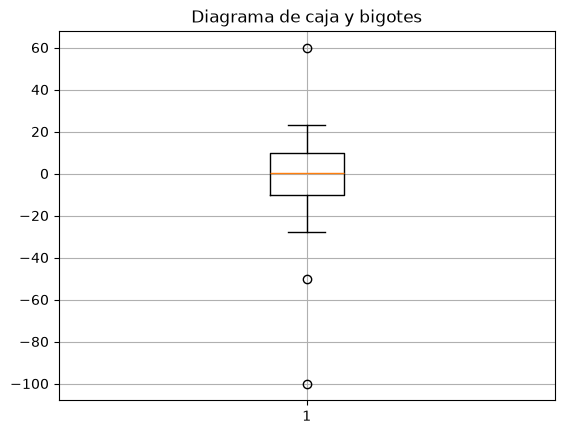

In [5]:
# Dibujamos una caja de bigotes para ver los datos

plt.boxplot(X)
plt.grid()
plt.title("Diagrama de caja y bigotes")
plt.show()

**Interpretación:** la caja es angosta y está cerca de 0. Los puntos fuera de los bigotes coinciden con los valores atípicos que encontramos con el RIC.

### Medidas de dispersión
* **Desviación típica** (`np.std`): cuánto se alejan los datos de la media, en las mismas unidades.
* **Varianza:** la desviación típica elevada al cuadrado.

In [6]:
# Medidas de dispersión
desvest = np.std(X)
print('Desviación típica: ', desvest)
print('Varianza: ', desvest**2)

Desviación típica:  33.521242681880096
Varianza:  1123.6737109375


**Interpretación:** la desviación típica es **33,52** y la varianza es **1123,67**. Son valores altos, lo que confirma que los datos están muy dispersos por los valores extremos.

### Medidas de distribución: asimetría y curtosis
* **Asimetría** (`stats.skew`): hacia qué lado se alarga la cola. Positiva es hacia la derecha y negativa hacia la izquierda.
* **Curtosis** (`stats.kurtosis`): qué tan puntiaguda o aplanada es la distribución comparada con la normal.
  * Mayor que 0: **leptocúrtica**.
  * Menor que 0: **platicúrtica**.
  * Igual a 0: **mesocúrtica**.
* Con `fisher=True` la curtosis se mide respecto a la normal, que vale 0.

In [7]:
# Medidas de distribución
asimetria = stats.skew(X)
curtosis = stats.kurtosis(X, fisher=True) 
print('Asimetría ', np.round(asimetria, 4))
print('Curtosis ', np.round(curtosis, 4))
if curtosis>0:
    print('Distribución Leptocúrtica')
elif curtosis<0:
    print('Distribución Platicúrtica')
else:
    print('Distribución Mesocúrtica')

Asimetría  -1.1302
Curtosis  2.2858
Distribución Leptocúrtica


**Interpretación:** la asimetría es **-1,1302**, negativa: la cola va hacia la izquierda, sobre todo por el valor -100. La curtosis es **2,2858**, mayor que 0, así que la distribución es **leptocúrtica**: tiene colas pesadas por los valores extremos.

### Aplicación con el dataset Iris
Cargamos el dataset **Iris** (medidas de flores de tres especies) y separamos los atributos en `X` y la clase en `y`.
* **Pregunta 1:** calculamos la asimetría de la *longitud del pétalo* (`X[:, 2]`).
* **Pregunta 2:** calculamos la curtosis del *ancho del sépalo* (`X[:, 1]`).
* Con `if / elif / else` mostramos un mensaje según el signo del resultado.

In [8]:
# Cargar el set de datos de Iris
from sklearn import datasets
from pprint import pprint
from scipy.stats import skew, kurtosis

iris = datasets.load_iris()
#pprint(iris)
X = iris.data
y = iris.target
# ¿Qué tipo de asimetría se observa en la variable "longitud del pétalo"?
#???
longitud_petalo = X[:, 2]
asimetria = skew(longitud_petalo)

print("Asimetría:", asimetria)

if asimetria > 0:
    print("La variable presenta asimetría positiva (sesgo hacia la derecha).")
elif asimetria < 0:
    print("La variable presenta asimetría negativa (sesgo hacia la izquierda).")
else:
    print("La variable tiene una distribución simétrica.")
# ¿A qué tipo de distribución se ajusta la variable "ancho del sépalo", según␣su curtosis?
#???
ancho_sepalo = X[:, 1]
curt = kurtosis(ancho_sepalo)
print("Curtosis:", curt)

if curt > 0:
    print("La distribución es leptocúrtica.")
elif curt < 0:
    print("La distribución es platicúrtica.")
else:
    print("La distribución es mesocúrtica.")

Asimetría: -0.2721276664567214
La variable presenta asimetría negativa (sesgo hacia la izquierda).
Curtosis: 0.18097631752246768
La distribución es leptocúrtica.


**Interpretación:**
* **Longitud del pétalo:** asimetría de **-0,2721**, negativa pero leve. Está cerca de 0, así que la distribución es casi simétrica.
* **Ancho del sépalo:** curtosis de **0,1810**. Por el signo es leptocúrtica, pero al estar tan cerca de 0 se parece mucho a una distribución normal.

### Ejercicio extra: media y desviación típica por clase
* Guardamos los nombres de las variables y las clases únicas con `np.unique(y)`.
* Con un ciclo `for` recorremos cada clase, filtramos sus datos con `X[y == clase]` y calculamos la media y la desviación típica de cada variable (`axis=0`).
* Con `plt.errorbar` graficamos: el punto es la media y la barra vertical es la desviación típica.

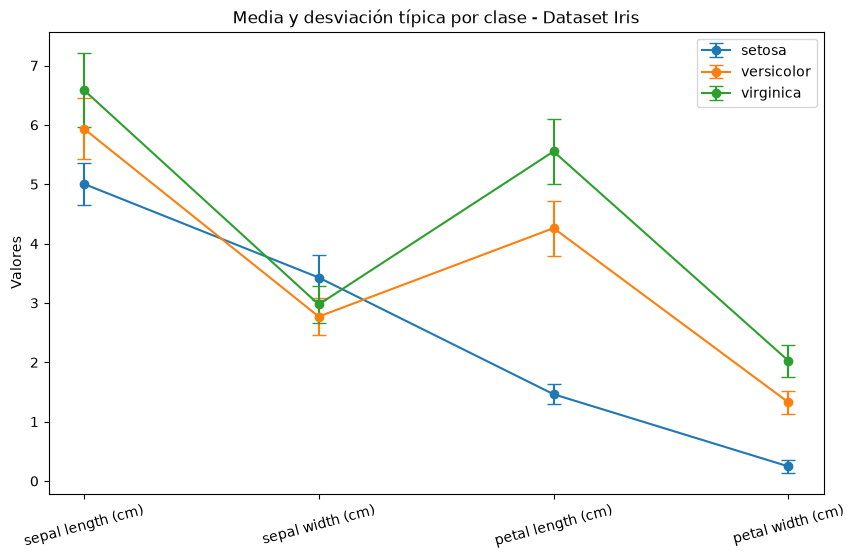

In [9]:
# EJERCICIO EXTRA SOBRE EL DATASET DE IRIS
# Extraer la media y la desviación típica de cada variable en función de la␣clase y representarlo en un gráfico (plt.errorbar)
# Nombres de variables
variables = iris.feature_names
# Clases
clases = np.unique(y)
# Crear figura
plt.figure(figsize=(10,6))
# Recorrer cada clase
for clase in clases:
    # Filtrar datos por clase
    datos_clase = X[y == clase]

    # Calcular media
    media = np.mean(datos_clase, axis=0)

    # Calcular desviación típica
    desviacion = np.std(datos_clase, axis=0)

    # Graficar con barras de error
    plt.errorbar(
        range(len(variables)),
        media,
        yerr=desviacion,
        marker='o',
        capsize=5,
        label=iris.target_names[clase]
    )
    
# Configuración del gráfico
plt.xticks(range(len(variables)), variables, rotation=15)
plt.ylabel("Valores")
plt.title("Media y desviación típica por clase - Dataset Iris")
plt.legend()

plt.show()

**Interpretación:** las tres especies se separan sobre todo en las variables del **pétalo**, donde sus medias son muy distintas. La *setosa* tiene los pétalos mucho más pequeños y casi no varían. En las variables del **sépalo** las barras se traslapan más. Por eso las medidas del pétalo sirven mejor para distinguir las especies.